In [1]:
import os
from collections import Counter

racine = "/kaggle/input"
images = []
for dossier, _, fichiers in os.walk(racine):
    for f in fichiers:
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            images.append(os.path.join(dossier, f))

print("Nombre d'images :", len(images))
print("Formats :", Counter(os.path.splitext(p)[1].lower() for p in images))
print("Sous-dossiers :", Counter(os.path.dirname(p) for p in images))

Nombre d'images : 1560
Formats : Counter({'.jpg': 1542, '.jpeg': 18})
Sous-dossiers : Counter({'/kaggle/input/datasets/anassiguedmi/moroccan-zellige/moroccan-zellige/train/true': 697, '/kaggle/input/datasets/anassiguedmi/moroccan-zellige/moroccan-zellige/train/false': 405, '/kaggle/input/datasets/anassiguedmi/moroccan-zellige/moroccan-zellige/test/true': 143, '/kaggle/input/datasets/anassiguedmi/moroccan-zellige/moroccan-zellige/validation/true': 143, '/kaggle/input/datasets/anassiguedmi/moroccan-zellige/moroccan-zellige/test/false': 86, '/kaggle/input/datasets/anassiguedmi/moroccan-zellige/moroccan-zellige/validation/false': 86})


Tailles les plus fréquentes (largeur, hauteur) : [((256, 256), 1560)]


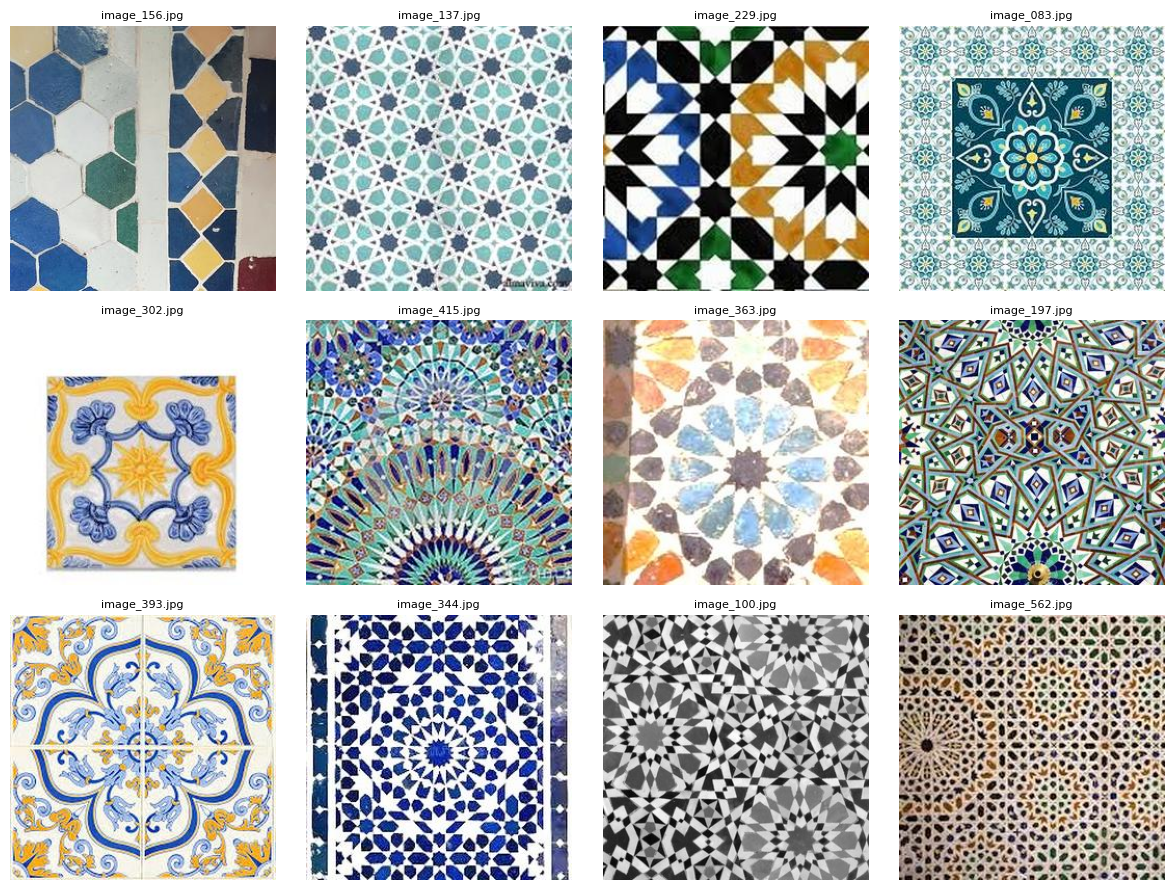

In [2]:
from PIL import Image
import matplotlib.pyplot as plt
import random

tailles = Counter()
for p in images:
    with Image.open(p) as im:
        tailles[im.size] += 1
print("Tailles les plus fréquentes (largeur, hauteur) :", tailles.most_common(10))

random.seed(0)
echantillon = random.sample(images, 12)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, p in zip(axes.flat, echantillon):
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(os.path.basename(p)[:20], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

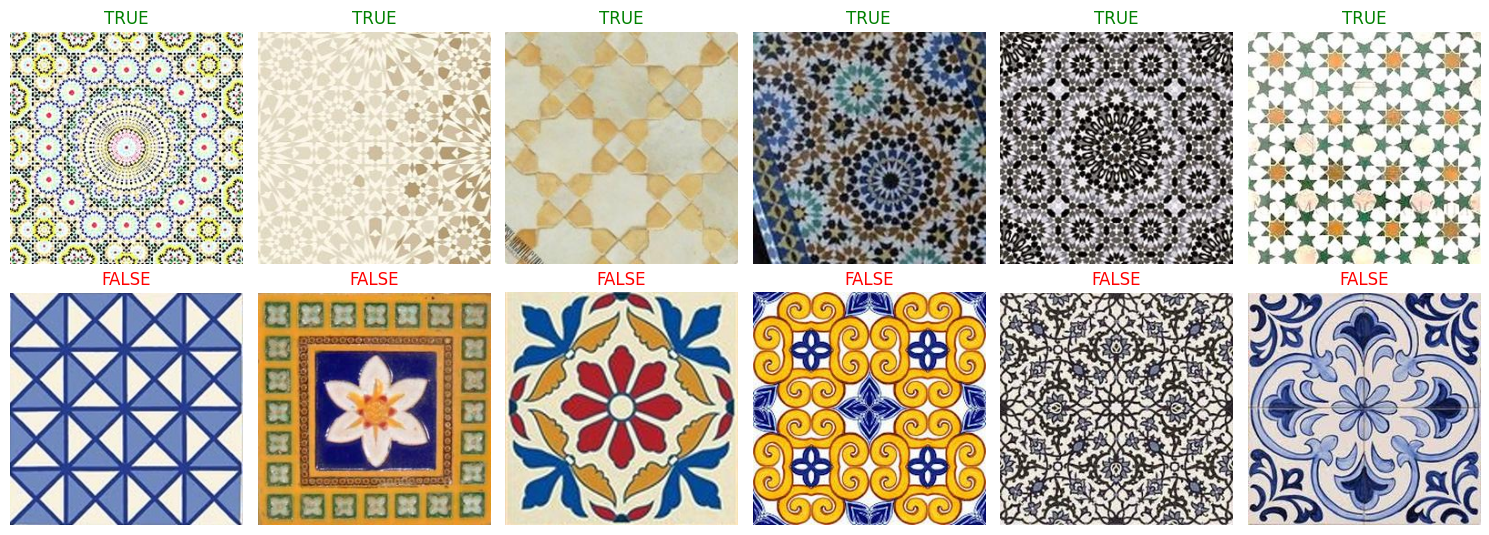

Images en niveaux de gris parmi les true : 0


In [3]:
true_imgs  = [p for p in images if "/true/" in p]
false_imgs = [p for p in images if "/false/" in p]

random.seed(1)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, p in zip(axes[0], random.sample(true_imgs, 6)):
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title("TRUE", color="green"); ax.axis("off")
for ax, p in zip(axes[1], random.sample(false_imgs, 6)):
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title("FALSE", color="red"); ax.axis("off")
plt.tight_layout(); plt.show()

gris = sum(1 for p in true_imgs if Image.open(p).mode == "L")
print("Images en niveaux de gris parmi les true :", gris)

In [4]:
import numpy as np

TAILLE = 128

def charger(split):
    chemins = sorted(p for p in true_imgs if f"/{split}/" in p)
    X = np.stack([np.array(Image.open(p).convert("RGB").resize((TAILLE, TAILLE), Image.BICUBIC))
                  for p in chemins])
    return X, chemins

X_train, ch_train = charger("train")
X_val,   ch_val   = charger("validation")
X_test,  ch_test  = charger("test")
print("train :", X_train.shape, "| val :", X_val.shape, "| test :", X_test.shape)

np.savez_compressed("/kaggle/working/zellige_128.npz",
                    train=X_train, val=X_val, test=X_test)
print("Fichier sauvegardé ✔")

train : (697, 128, 128, 3) | val : (143, 128, 128, 3) | test : (143, 128, 128, 3)
Fichier sauvegardé ✔


In [7]:
import cv2

def masque_central(ratio, H=TAILLE):
    c = int(round(H * np.sqrt(ratio)))          # côté du carré pour couvrir `ratio` de l'image
    m = np.zeros((H, H), np.uint8)
    d = (H - c) // 2
    m[d:d+c, d:d+c] = 1
    return m

def masque_carre(ratio, rng, H=TAILLE):
    c = int(round(H * np.sqrt(ratio)))
    x, y = rng.integers(0, H - c + 1, size=2)    # position aléatoire
    m = np.zeros((H, H), np.uint8)
    m[y:y+c, x:x+c] = 1
    return m

def masque_irregulier(ratio, rng, H=TAILLE):
    m = np.zeros((H, H), np.uint8)
    while m.mean() < ratio:                      # on ajoute des traits jusqu'à atteindre la surface voulue
        x, y = rng.integers(0, H, size=2)
        for _ in range(rng.integers(4, 10)):
            angle = rng.uniform(0, 2 * np.pi)
            L = rng.integers(10, 30)
            x2 = int(np.clip(x + L * np.cos(angle), 0, H - 1))
            y2 = int(np.clip(y + L * np.sin(angle), 0, H - 1))
            cv2.line(m, (int(x), int(y)), (x2, y2), 1, int(rng.integers(8, 16)))
            x, y = x2, y2
            if m.mean() >= ratio:
                break
    return m

def creer_masque(type_, ratio, rng):
    if type_ == "central":  return masque_central(ratio)
    if type_ == "carre":    return masque_carre(ratio, rng)
    return masque_irregulier(ratio, rng)

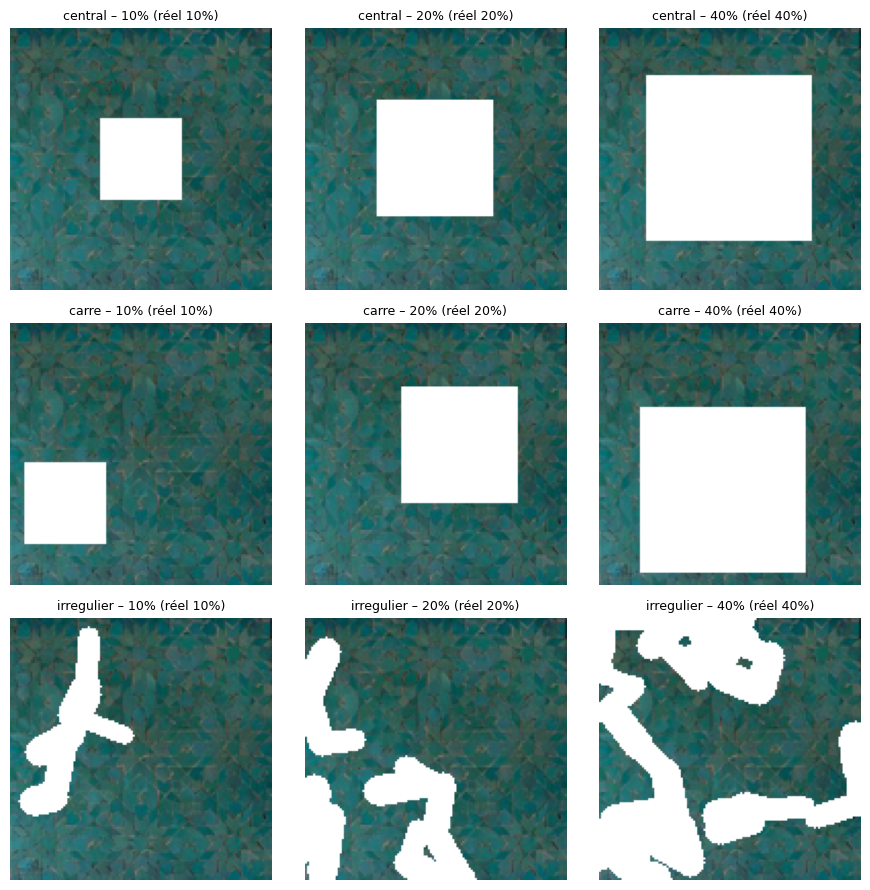

In [8]:
rng = np.random.default_rng(42)
img = X_test[0]
types, ratios = ["central", "carre", "irregulier"], [0.10, 0.20, 0.40]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, t in enumerate(types):
    for j, r in enumerate(ratios):
        m = creer_masque(t, r, rng)
        abimee = img.copy()
        abimee[m == 1] = 255                     # la zone effacée apparaît en blanc
        axes[i, j].imshow(abimee)
        axes[i, j].set_title(f"{t} – {int(r*100)}% (réel {m.mean()*100:.0f}%)", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout(); plt.show()

In [10]:
rng = np.random.default_rng(2026)
masques_test = {}
for t in types:
    for r in ratios:
        masques_test[f"{t}_{int(r*100)}"] = np.stack([creer_masque(t, r, rng) for _ in range(len(X_test))])

np.savez_compressed("/kaggle/working/masques_test_128.npz", **masques_test)
print({k: v.shape for k, v in masques_test.items()})

{'central_10': (143, 128, 128), 'central_20': (143, 128, 128), 'central_40': (143, 128, 128), 'carre_10': (143, 128, 128), 'carre_20': (143, 128, 128), 'carre_40': (143, 128, 128), 'irregulier_10': (143, 128, 128), 'irregulier_20': (143, 128, 128), 'irregulier_40': (143, 128, 128)}
